# Word Frequency

Which words do characters use most, and does it change between groups? We use the cleaned speeches from `data_cleaning.ipynb` (lemmatized, stopwords removed). Counting is from 6-2, relative frequency from 7-1, and the bar charts from 3-2.

Two comparisons:
1. **Court vs Household** (Question 2): do the two worlds of the play talk about different things?
2. **Viola with Orsino vs Viola with Olivia** (Question 3): does Viola talk differently depending on who she is in front of while she is disguised as Cesario?

In [1]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

## Load the cleaned speeches

In [2]:
speeches = pd.read_csv('data/twelfth_night_speeches.csv')

# short speeches like "I will." have no words left after cleaning, so they are empty
speeches['clean_text'] = speeches['clean_text'].fillna('')

print(len(speeches), 'speeches')
speeches.head()

926 speeches


,act,scene,speaker,lines,text,clean_text
0,1,1,ORSINO,15,"If music be the food of love, play on.\nGive m...",music food love play give excess surfeit appet...
1,1,1,CURIO,1,"Will you go hunt, my lord?",go hunt lord
2,1,1,ORSINO,1,"What, Curio?",curio
3,1,1,CURIO,1,The hart.,hart
4,1,1,ORSINO,7,"Why, so I do, the noblest that I have.\nO, whe...",noble mine eye see olivia first methought purg...


The WordNet lemmatizer made a couple of mistakes: it turned "alas" into "ala" and "us" into "u" (it thinks they are plurals). We fix those two before counting.

In [3]:
fixes = {'ala': 'alas', 'u': 'us'}

def get_words(df):
    words = ' '.join(df['clean_text']).split()
    return [fixes.get(w, w) for w in words]

## Most common words in the whole play

In [4]:
all_words = get_words(speeches)
all_counts = Counter(all_words)

print('Total words:', len(all_words))
print('Unique words:', len(all_counts))
all_counts.most_common(20)

Total words: 8366
Unique words: 2426


[('sir', 180),
 ('come', 103),
 ('good', 94),
 ('love', 87),
 ('lady', 81),
 ('let', 78),
 ('well', 68),
 ('man', 68),
 ('make', 67),
 ('fool', 67),
 ('say', 63),
 ('go', 61),
 ('one', 61),
 ('know', 56),
 ('give', 55),
 ('see', 49),
 ('take', 45),
 ('like', 43),
 ('think', 40),
 ('lord', 39)]

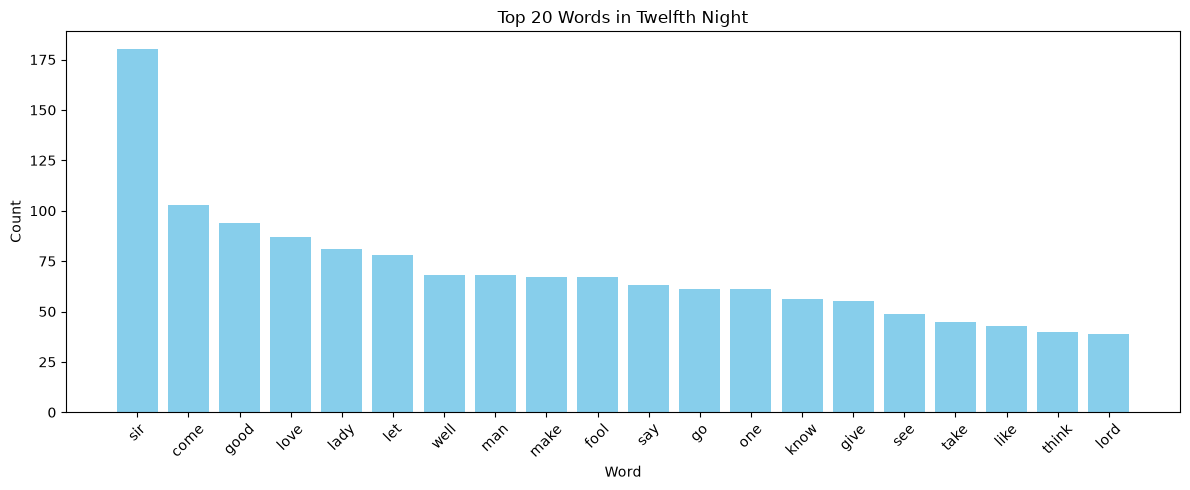

In [5]:
top_20 = all_counts.most_common(20)
words, counts = zip(*top_20)

plt.figure(figsize=(12, 5))
plt.bar(words, counts, color='skyblue')
plt.title('Top 20 Words in Twelfth Night')
plt.xlabel('Word')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Most of these are everyday words (sir, come, good, let, well). Only "love" and "lady" tell us anything about the play. Counting the whole play mixes everyone together, so next we compare groups of characters.

## Court vs Household

We use the same groups as our topic statement:
- **Court:** Orsino, Olivia, Viola
- **Household:** Sir Toby, Sir Andrew, Maria, Malvolio

Feste (FOOL) is left out because he moves between both groups (see the network section).

In [6]:
court = ['ORSINO', 'OLIVIA', 'VIOLA']
household = ['TOBY', 'ANDREW', 'MARIA', 'MALVOLIO']

court_words = get_words(speeches[speeches['speaker'].isin(court)])
household_words = get_words(speeches[speeches['speaker'].isin(household)])

court_counts = Counter(court_words)
household_counts = Counter(household_words)

print('Court words:', len(court_words))
print('Household words:', len(household_words))

Court words: 2764
Household words: 3072


The groups don't say the same number of words, so we compare **words per 1,000** (relative frequency, from 7-1) instead of raw counts. For example, "love" appears 57 times in about 2,800 court words, which is about 20 per 1,000 words.

In [7]:
def per_1000(counts, total):
    return {word: count / total * 1000 for word, count in counts.items()}

court_rate = per_1000(court_counts, len(court_words))
household_rate = per_1000(household_counts, len(household_words))

print('Court top 15:')
for word, count in court_counts.most_common(15):
    print(f'  {word}: {count} ({court_rate[word]:.1f} per 1,000)')

print('\nHousehold top 15:')
for word, count in household_counts.most_common(15):
    print(f'  {word}: {count} ({household_rate[word]:.1f} per 1,000)')

Court top 15:
  love: 57 (20.6 per 1,000)
  sir: 29 (10.5 per 1,000)
  come: 28 (10.1 per 1,000)
  lord: 27 (9.8 per 1,000)
  well: 26 (9.4 per 1,000)
  lady: 25 (9.0 per 1,000)
  man: 24 (8.7 per 1,000)
  give: 23 (8.3 per 1,000)
  know: 23 (8.3 per 1,000)
  much: 21 (7.6 per 1,000)
  heart: 20 (7.2 per 1,000)
  one: 20 (7.2 per 1,000)
  make: 20 (7.2 per 1,000)
  good: 20 (7.2 per 1,000)
  let: 20 (7.2 per 1,000)

Household top 15:
  sir: 72 (23.4 per 1,000)
  come: 48 (15.6 per 1,000)
  good: 36 (11.7 per 1,000)
  let: 35 (11.4 per 1,000)
  lady: 34 (11.1 per 1,000)
  fool: 30 (9.8 per 1,000)
  go: 29 (9.4 per 1,000)
  say: 28 (9.1 per 1,000)
  make: 28 (9.1 per 1,000)
  man: 27 (8.8 per 1,000)
  toby: 24 (7.8 per 1,000)
  see: 24 (7.8 per 1,000)
  one: 23 (7.5 per 1,000)
  well: 22 (7.2 per 1,000)
  hand: 21 (6.8 per 1,000)


Both lists still share a lot of words. To find what makes each group different, we take the rate in the court minus the rate in the household for every word. A big positive number means the court uses the word much more, a big negative number means the household does.

We only keep words used at least 8 times in total, so rare words don't take over the chart (7-1: most words are rare, so methods usually ignore words below a minimum count).

In [8]:
rows = []
for word in set(court_counts) | set(household_counts):
    if court_counts[word] + household_counts[word] >= 8:
        rows.append({'word': word,
                     'court': court_counts[word],
                     'household': household_counts[word],
                     'difference': court_rate.get(word, 0) - household_rate.get(word, 0)})

compare = pd.DataFrame(rows)

# when two words have the same difference, sort them alphabetically so the result is the same every time
more_court = compare.sort_values(['difference', 'word'], ascending=[False, True]).head(15)
more_household = compare.sort_values(['difference', 'word'], ascending=[True, True]).head(15)

more_court

,word,court,household,difference
69,love,57,14,16.064995
76,lord,27,4,8.466368
108,heart,20,4,5.933807
103,much,21,7,5.319039
68,cesario,14,1,4.739602
107,woman,14,1,4.739602
15,mine,15,3,4.450355
6,master,14,3,4.088561
66,may,19,10,3.618887
51,yet,17,8,3.546340


In [9]:
more_household

,word,court,household,difference
141,sir,29,72,-12.945459
77,toby,2,24,-7.088911
37,come,28,48,-5.494754
138,fool,12,30,-5.424091
97,see,8,24,-4.918144
132,knight,2,17,-4.810265
120,niece,1,15,-4.521018
49,good,20,36,-4.482860
121,go,14,29,-4.374981
8,hand,7,21,-4.303376


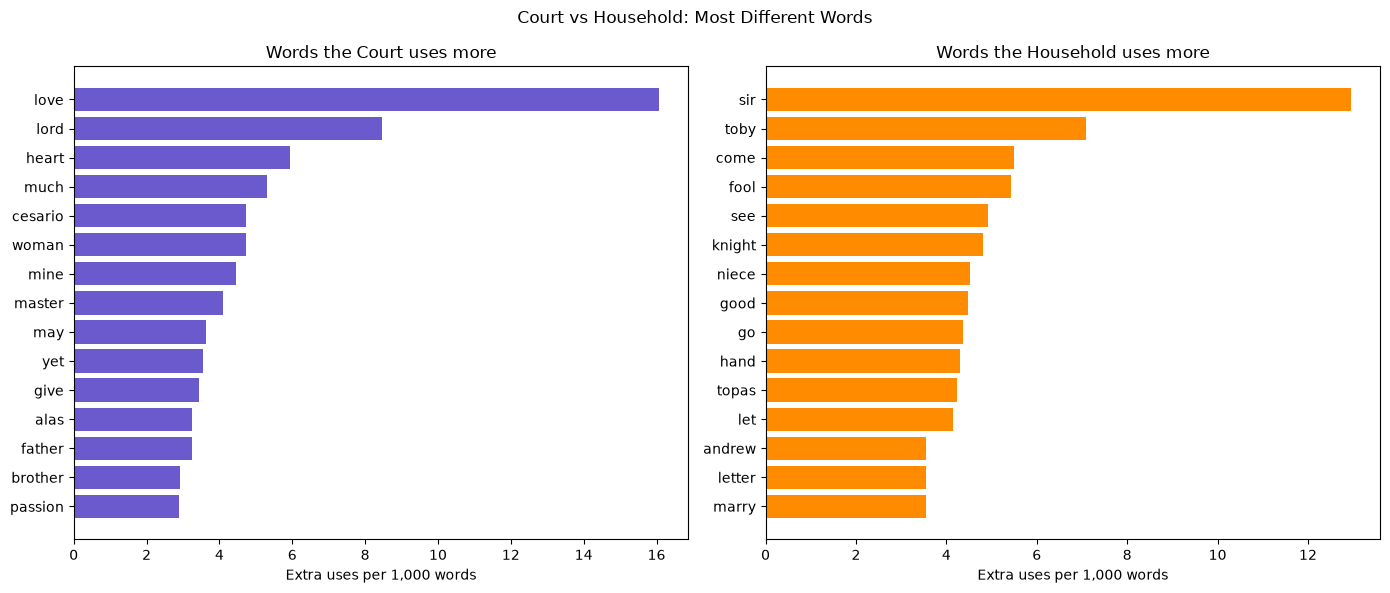

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# reverse so the biggest bar is at the top
axes[0].barh(more_court['word'][::-1], more_court['difference'][::-1], color='slateblue')
axes[0].set_title('Words the Court uses more')
axes[0].set_xlabel('Extra uses per 1,000 words')

axes[1].barh(more_household['word'][::-1], -more_household['difference'][::-1], color='darkorange')
axes[1].set_title('Words the Household uses more')
axes[1].set_xlabel('Extra uses per 1,000 words')

plt.suptitle('Court vs Household: Most Different Words')
plt.tight_layout()
plt.savefig('figures/court_vs_household_words.png', dpi=200)
plt.show()

**What this shows:** the court talks about feelings and family: love, heart, woman, father, brother, passion, alas. "Love" is used 57 times by the court and only 14 times by the household. The household talks about rank and their joke on Malvolio: sir, knight, niece, letter (the fake letter), and Topas (Feste pretending to be Sir Topas). The two groups talk about different things.

## Viola with Orsino vs Viola with Olivia

Viola is disguised as Cesario from Act 1 Scene 4 until the end, so almost everything she says is said "as Cesario". To see if the disguise changes how she talks, we split her speeches by the scenes where she is with Orsino and the scenes where she goes to Olivia.

- **With Orsino:** Act 1 Scene 4, Act 2 Scene 4
- **With Olivia:** Act 1 Scene 5, Act 3 Scene 1

In [11]:
viola = speeches[speeches['speaker'] == 'VIOLA']

orsino_scenes = [(1, 4), (2, 4)]
olivia_scenes = [(1, 5), (3, 1)]

def in_scenes(df, scene_list):
    keep = [(act, scene) in scene_list for act, scene in zip(df['act'], df['scene'])]
    return df[keep]

with_orsino = get_words(in_scenes(viola, orsino_scenes))
with_olivia = get_words(in_scenes(viola, olivia_scenes))

orsino_counts = Counter(with_orsino)
olivia_counts = Counter(with_olivia)

print('Viola with Orsino:', len(with_orsino), 'words')
print('Viola with Olivia:', len(with_olivia), 'words')

Viola with Orsino: 136 words
Viola with Olivia: 441 words


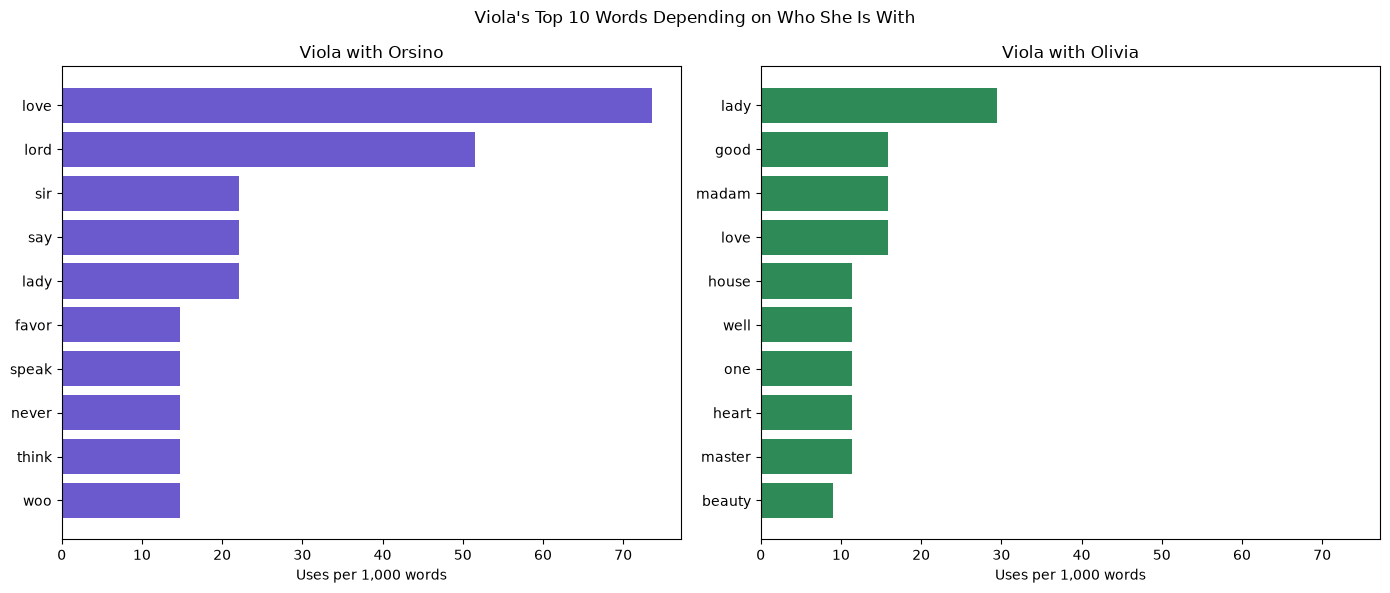

In [12]:
orsino_rate = per_1000(orsino_counts, len(with_orsino))
olivia_rate = per_1000(olivia_counts, len(with_olivia))

top_orsino = orsino_counts.most_common(10)
top_olivia = olivia_counts.most_common(10)

# same x-axis on both sides so the bars can be compared
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

words = [w for w, c in top_orsino][::-1]
axes[0].barh(words, [orsino_rate[w] for w in words], color='slateblue')
axes[0].set_title('Viola with Orsino')
axes[0].set_xlabel('Uses per 1,000 words')

words = [w for w, c in top_olivia][::-1]
axes[1].barh(words, [olivia_rate[w] for w in words], color='seagreen')
axes[1].set_title('Viola with Olivia')
axes[1].set_xlabel('Uses per 1,000 words')

plt.suptitle("Viola's Top 10 Words Depending on Who She Is With")
plt.tight_layout()
plt.savefig('figures/viola_orsino_vs_olivia.png', dpi=200)
plt.show()

Some words are tied (lots of words appear only twice with Orsino), so the order inside a tie doesn't mean anything. A table of a few chosen words is easier to read:

In [13]:
chosen = ['love', 'lord', 'woman', 'father', 'daughter', 'lady', 'madam', 'master', 'servant', 'beauty']

table = pd.DataFrame({
    'with Orsino (count)': [orsino_counts[w] for w in chosen],
    'with Orsino (per 1,000)': [round(orsino_rate.get(w, 0), 1) for w in chosen],
    'with Olivia (count)': [olivia_counts[w] for w in chosen],
    'with Olivia (per 1,000)': [round(olivia_rate.get(w, 0), 1) for w in chosen],
}, index=chosen)

table

,with Orsino (count),"with Orsino (per 1,000)",with Olivia (count),"with Olivia (per 1,000)"
love,10,73.5,7,15.9
lord,7,51.5,2,4.5
woman,2,14.7,1,2.3
father,2,14.7,0,0.0
daughter,2,14.7,0,0.0
lady,3,22.1,13,29.5
madam,0,0.0,7,15.9
master,0,0.0,5,11.3
servant,0,0.0,4,9.1
beauty,0,0.0,4,9.1


**What this shows:** with Orsino, Viola says "love" about 74 times per 1,000 words, almost 5 times more than with Olivia (about 16). She also says woman, father and daughter, which come from Act 2 Scene 4 ("My father had a daughter loved a man"), where she almost tells Orsino who she really is. With Olivia she keeps to the language of a servant: lady, madam, master, servant, beauty. With Olivia she stays in character as Cesario. With Orsino her real feelings show.

## Limitations

- The numbers are small. Viola only has 136 words (after cleaning) in the scenes with Orsino, so one or two speeches can change the results a lot.
- Splitting by scene is not perfect. In Act 1 Scene 5 and Act 3 Scene 1 Viola also talks to Maria, Feste and Sir Toby, so words like "fool" and "tabor" come from those conversations, not from Olivia.
- We chose the Court and Household groups ourselves. Putting Olivia in the court group is a choice, since the household is her house.
- Lemmatizing is not always right for Early Modern English (we fixed "alas" and "us", but there may be more).
- Word counts don't show meaning. "Love" can be serious (Orsino) or a joke (Sir Toby), and counting treats them the same.